## Problem 1: barometer vs. accelerometer
*50-65 points*

In this problem, we will use your phone's barometer and accelerometer to measure the motion of an elevator. 

#### Prerequisites

Download the phyphox app on your phone. Spend a minute getting familiar with the app: 

- In a given "experiment," press "play" to start recording data and "pause" to stop recording. 
- From a paused experiment, make sure you can export the data and transfer it to your computer, e.g., by email/Dropbox/your preferred method. 

We'll use a custom experiment to collect acceleration and pressure simultaneously. You can either scan the QR code, or just hit the "+" icon and create a "simple experiment" with accelerometer (without g) and pressure data. Leave the time setting at "0" to specify maximum data rate. 

<img src="../qr_phyphox.png" width="300px"/>

Link: <https://dryu.web.cern.ch/dryu/public/elevator_a_p.phyphox>


### Problem 1a: data collection and visualization
*10 points*

Find an elevator, ideally with at least 5 floors (Cook/Hochstetter are the closest to Fronczak; note that floor 5 is inaccessible). Lay your phone flat on the ground with the screen up (consider using a paper towel, the floor may be dirty). **Using the accelerometer+pressure phyphox experiment, collect simultaneous barometer and accelerometer information versus time for 2x2=4 configurations**:

1. Up versus down
2. One trip versus stopping at each floor

Tips: 

- I suggest taking a couple trials to ensure you have good data, but don't go too crazy and spend hours on this.
- Make sure you include about 5-10 seconds of "rest" data at the start and end of the elevator ride, where the elevator is stationary and the doors are not moving. This gives you good endpoint data for the exercise.
- Depending on your phone, the barometer and accelerometer will probably have different time granularity (the accelerometer has much higher sampling frequency). Make sure to use the correct timestamps for each input data. Further, the time measurements will ideally be equally spaced; if not, you may have to use `np.interp` to convert to equal spacing. 

Transfer the data to your computer. In the notebook `midterm/problem1/problem1.ipynb`, **visualize your data in one or more matplotlib plots**. The pressure and acceleration data should be plotted on similar time axes to allow for easy comparison. I also suggest overlaying some of your various experimental configurations and trials, to avoid having dozens of individual plots. 


### Problem 1b: data analysis (accelerometer)
*20 points*

Using a trapezoid integrator, **integrate the accelerometer data to obtain velocity** ($v_{\text{acc}}$), then **integrate again to obtain position** ($z_{\text{acc}}$). Identify the correct acceleration component and its sign: it's probably $a_z$, the direction perpendicular to your screen, but it may depend on your phone.

Note: in class, we covered integration with fixed limits; here, we are doing a cumulative integral, e.g., $v(t) = \int_0^t a(t') dt'$. The algorithm is the same, we are just reporting the results at each step of the integral. You might want to use `scipy.integrate.cumulative_trapezoid`.

 **Make a matplotlib plot** showing the position, velocity, and acceleration on the same time axis (for example, a 3-panel plot stacked vertically). 

One big problem with the accelerometer method is that sensor bias has a larger impact on the velocity and position. One easy way to see this is that the velocity will likely not be 0 where expected (e.g., when the elevator stops at floors). For each experiment, **correct your velocity data for this bias** with a simple method: draw a linear function between the velocities at the start and end of the experiment (which, again, we know should be 0), and subtract that line from the data. (You'll have to set a start and end time for this linear correction function; just estimate that as best you can.) Then, **integrate the corrected velocity** to obtain the corrected position. **Plot the results.** 

Finally, **determine the floor spacing and total height** of your elevator ride. Include the standard deviation across your experiments. 


### Problem 1c: data analysis (barometer)
*20 points*

Perhaps surprisingly, the barometer in most phones is actually pretty good. Over small distances, the pressure and height have a linear relationship:

$$
\rho_0 g \Delta h \approx - \Delta P
$$

where $g=9.81\,\text{m/s}^2$ and $\rho_0\approx P_0M/(RT)$ is the air density at the reference pressure $P_0$. Using:

- $R=8.314\,\text{J}/\text{mol}\,\text{K}$
- $M=0.02896\,\text{kg}/\text{mol}$
- $T=22\,\text{C}=295.15\,\text{K}$
- $P_0=1000\,\text{hPa}$

we have $\rho_0\approx 1.180\,\text{kg}/\text{m}^3$. Optionally, feel free to correct this value for your measured $P_0$ and/or $T$, but the impact is small. 

**Use the formula to convert pressure ($P$) to height ($z_P$)**. Similarly to (1b), plot $z_P$ vs. time, and determine the floor spacing and total height. Compare with the accelerometer results, and comment on any differences. Note, phyphox exports pressure in hPa=100 Pa. 

### Problem 1d: velocity from barometer
*15 points*

**PHY505 students only**

We can differentiate the barometric height ($z_P$) to obtain velocity. However, the data is quite noisy, so naively taking the derivative will give useless results. Instead, **use FFT to smooth the data** for one of your experiments. Remember the steps:

- The data have to be spaced uniformly. Check your barometer time data, and if not uniform, use `np.interp` to make it uniform. 
- Prepare data for FFT: subtract the offset (or even better, subtract the line through the first and last points), pad the data to the nearest power of 2. Note: windowing may not work well here, as it can cause noise to blow up near the edges. If you do use a window, make sure to avoid that noise.
- Take the FFT
- Suppress the noise with a low-pass filter
- Take the inverse FFT
- Reverse the transformations you applied in step 1 (i.e. the window function and offset subtraction)

Then, take the numerical derivative of the smoothed data to obtain velocity. Plot it against the accelerometer results, and comment on any differences.


## Starter code: loading phyphox data

Export your data from phyphox as **CSV (Comma, decimal point)**. phyphox gives you a zip file; unzip it into a folder next to this notebook (one folder per trial, e.g. `data/up_onetrip_1/`). Each folder contains `Acceleration.csv` and `Pressure.csv` (plus a `meta/` folder you can ignore).

The folder `example_data/` contains a **fake** example ride (up 4 floors, stopping at each floor) in the same format, so you can test your code before collecting data. Do not use it for your answers!

accelerometer: 2828 samples, mean spacing 16.7 ms (min 16.7, max 16.8)
barometer:     1882 samples, mean spacing 25.14 mss(min 25.1, max 25.2)


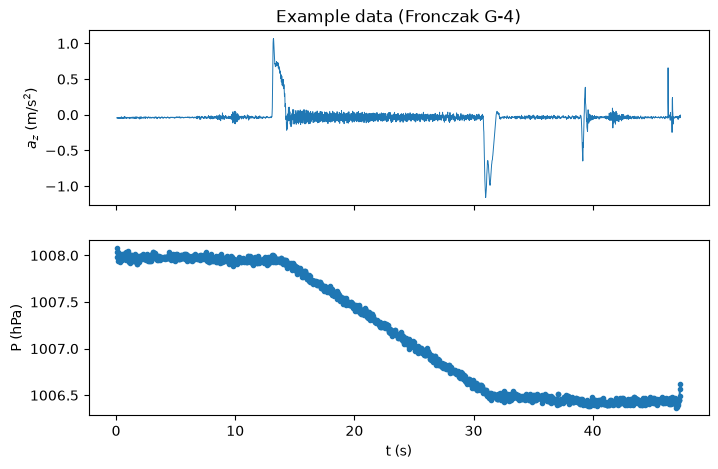

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid


def load_phyphox(folder):
    """Load an unzipped phyphox CSV export of the elevator experiment.

    Returns
    -------
    t_a : array, accelerometer timestamps (s)
    a   : array of shape (N, 3), acceleration without g, components x, y, z (m/s^2)
    t_P : array, barometer timestamps (s)
    P   : array, pressure (hPa)
    """
    acc = np.genfromtxt(f"{folder}/Acceleration.csv", delimiter=",", skip_header=1)
    prs = np.genfromtxt(f"{folder}/Pressure.csv", delimiter=",", skip_header=1)
    return acc[:, 0], acc[:, 1:4], prs[:, 0], prs[:, 1]


t_a, a, t_P, P = load_phyphox("example_data")
print(f"accelerometer: {t_a.size} samples, mean spacing {np.diff(t_a).mean()*1e3:.1f} ms "
      f"(min {np.diff(t_a).min()*1e3:.1f}, max {np.diff(t_a).max()*1e3:.1f})")
print(f"barometer:     {t_P.size} samples, mean spacing {np.diff(t_P).mean()*1.e3:.2f} ms"
     f"(min {np.diff(t_P).min()*1e3:.1f}, max {np.diff(t_P).max()*1e3:.1f})")

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
axs[0].plot(t_a, a[:, 2], lw=0.7)
axs[0].set_ylabel("$a_z$ (m/s$^2$)")
axs[1].plot(t_P, P, ".-")
axs[1].set_ylabel("P (hPa)")
axs[1].set_xlabel("t (s)")
axs[0].set_title("Example data (Fronczak G-4)")
plt.show()

In [ ]:
# Problem 1a: data collection and visualization
# Step 1: load each of your experiments/trials with load_phyphox()
# Step 2: plot acceleration and pressure vs. time on aligned time axes (e.g. plt.subplots(..., sharex=True))
# Step 3: overlay configurations/trials where it helps


In [ ]:
# Problem 1b: accelerometer
# Step 1: pick the vertical acceleration component (and its sign)
# Step 2: integrate a -> v -> z with a cumulative trapezoid integrator
# Step 3: 3-panel plot of z, v, a vs. time
# Step 4: subtract a straight line from v so that v = 0 at the start and end rest periods; re-integrate to get z
# Step 5: floor spacing and total height, with the standard deviation across experiments


In [ ]:
# Problem 1c: barometer
R = 8.314       # J/(mol K)
M = 0.02896     # kg/mol
T = 295.15      # K
P0 = 1000e2     # Pa  (note: phyphox reports hPa)
g = 9.81        # m/s^2
rho0 = P0 * M / (R * T)
print(f"rho0 = {rho0:.3f} kg/m^3")

# Step 1: convert pressure to height, z_P = -(P - P_start) / (rho0 g)   [careful with hPa -> Pa]
# Step 2: plot z_P vs. time
# Step 3: floor spacing and total height; compare with the accelerometer results


In [ ]:
# Problem 1d: PHY505 students only (PHY410 extra credit)
# Step 1: make the barometer data uniformly spaced (np.interp) if needed
# Step 2: subtract the line through the first and last points; zero-pad to a power of 2
# Step 3: FFT, low-pass filter, inverse FFT; add the line back
# Step 4: numerical derivative of the smoothed z_P -> velocity
# Step 5: plot against the accelerometer velocity and comment
